# 06 - Inferential statistics
**Heat, Rain & Harvest.** Phase 6: turn the EDA patterns into tested statements, with honest uncertainty.

Main outcome: `yield_rel_anom` = wheat (or rice) yield as a fraction above/below the district's own trend.
Unit of observation: district-year (analysis sample, area >= 1,000 ha). Significance level alpha = 0.05.

**Caveat used throughout:** years of the same district are not independent, and districts in the same year share weather.
Simple tests (t, ANOVA, chi-square) assume independence, so their p-values are too optimistic. Sections 9-10 use
methods that respect this (cluster bootstrap, fixed effects with clustered errors), and those are the ones we trust.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.proportion import proportions_ztest
from src.config import PROCESSED, FIGURES, SEED
rng = np.random.default_rng(SEED)            # fixed seed: bootstrap results are reproducible
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
save = lambda fig, n: fig.savefig(FIGURES / f"{n}.png", bbox_inches="tight", dpi=150)

w = pd.read_parquet(PROCESSED / "model_wheat.parquet"); w = w[w.in_sample].copy()
r = pd.read_parquet(PROCESSED / "model_rice.parquet");  r = r[r.in_sample].copy()
within = lambda d, c: d[c] - d.groupby("unit_id")[c].transform("mean")   # deviation from own district mean
w["hot_dev"] = within(w, "mar_hot_days_35")
w["hot_march"] = w.hot_dev > 3                           # >= 3 more days > 35 C than the district usually has
r["rain_dev_pct"] = r.rain_jun_sep / r.groupby("unit_id").rain_jun_sep.transform("mean") - 1
r["drought"] = r.rain_dev_pct < -0.2                     # monsoon >= 20% below the district's normal
print(f"wheat n={len(w):,}  hot Marches={w.hot_march.sum():,}   rice n={len(r):,}  drought years={r.drought.sum():,}")

wheat n=9,793  hot Marches=2,220   rice n=13,052  drought years=3,047


## 1. Which distributions fit? (normal, Poisson, binomial)
### 1a. Normal: are yield anomalies normally distributed?

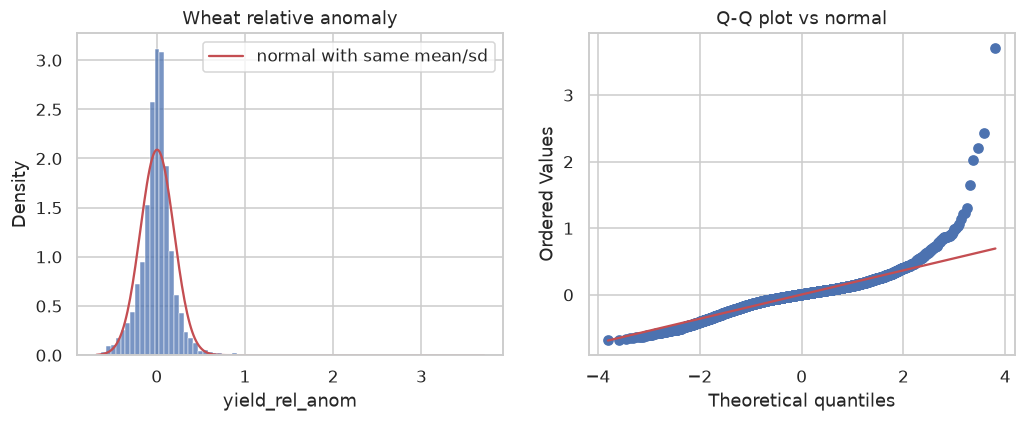

mean 0.0040  sd 0.1909  skew 1.57  excess kurtosis 23.14
D'Agostino K^2 = 4702.6, p = 0.00e+00
KS vs fitted normal: KstestResult(statistic=np.float64(0.0830163476220146), pvalue=np.float64(3.68651455461537e-59), statistic_location=np.float64(0.6694439663753122), statistic_sign=np.int8(1))


In [2]:
x = w.yield_rel_anom.dropna()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(x, bins=80, stat="density", ax=ax[0]); xs = np.linspace(x.min(), x.max(), 300)
ax[0].plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "r", label="normal with same mean/sd"); ax[0].legend(); ax[0].set_title("Wheat relative anomaly")
stats.probplot(x, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot vs normal")
save(fig, "06_normality_wheat"); plt.show()
print(f"mean {x.mean():.4f}  sd {x.std():.4f}  skew {stats.skew(x):.2f}  excess kurtosis {stats.kurtosis(x):.2f}")
k2, p = stats.normaltest(x); print(f"D'Agostino K^2 = {k2:.1f}, p = {p:.2e}")
print("KS vs fitted normal:", stats.kstest((x - x.mean()) / x.std(), "norm"))

With ~10,000 observations even tiny departures from normality are 'significant', so we judge by the Q-Q plot and
kurtosis: the tails are **heavier than normal** (more extreme good and bad years than a bell curve predicts).
Consequences: prefer robust/nonparametric checks alongside t-tests, and bootstrap confidence intervals.

### 1b. Poisson: number of days > 35 C in March

In [3]:
k = w.mar_hot_days_35.round().astype(int)
lam = k.mean()
print(f"mean {lam:.2f}, variance {k.var():.2f}  -> dispersion ratio {k.var()/lam:.1f} (Poisson needs 1)")
full = w.unit_id.value_counts(); full = full[full == 26].index                     # districts with all 26 years
typical = w[w.unit_id.isin(full)].groupby("unit_id").mar_hot_days_35.mean().pipe(lambda s: (s - s.median()).abs().idxmin())
sub = w[w.unit_id == typical].mar_hot_days_35.round().astype(int)                # one typical district, 26 years
print(f"single district ({len(sub)} years): mean {sub.mean():.2f}, variance {sub.var():.2f}, ratio {sub.var()/sub.mean():.2f}")

mean 8.66, variance 72.85  -> dispersion ratio 8.4 (Poisson needs 1)
single district (26 years): mean 7.46, variance 33.22, ratio 4.45


Pooled over India the counts are hugely **overdispersed** (variance >> mean), because districts have very different climates.
A Poisson model needs a constant rate, so it can only be judged within one district (next: formal chi-square test in section 5).

### 1c. Binomial: number of yield-loss years per district

In [4]:
g = w.groupby("unit_id").agg(n=("yield_loss", "count"), k=("yield_loss", "sum"))
g = g[g.n == 26]                                           # districts observed all 26 years
p_hat = g.k.sum() / g.n.sum()
print(f"{len(g)} districts with 26 years; loss probability p = {p_hat:.3f}; mean losses per district {g.k.mean():.2f} "
      f"(binomial expects {26*p_hat:.2f}); variance {g.k.var():.2f} (binomial expects {26*p_hat*(1-p_hat):.2f})")

249 districts with 26 years; loss probability p = 0.192; mean losses per district 5.00 (binomial expects 5.00); variance 6.77 (binomial expects 4.04)


## 2. z-scores: how unusual was a year?
z = (x - mean) / sd, using each district's own history. |z| > 2 happens about 5% of the time under normality.

In [5]:
w["z"] = (w.yield_t_ha - w.trend_full) / w.groupby("unit_id").yield_anom.transform("std")
print("share of district-years with |z| > 2:", round((w.z.abs() > 2).mean(), 3), " (normal: 0.046)")
print("share with z < -2 (severe losses) by year, top 5:")
print(w.assign(sev=w.z < -2).groupby("year").sev.mean().sort_values(ascending=False).head(5).round(3).to_string())

share of district-years with |z| > 2: 0.047  (normal: 0.046)
share with z < -2 (severe losses) by year, top 5:
year
2014    0.300
2015    0.098
2005    0.054
2021    0.037
2008    0.033


## 3. t-test vs z-test: do hot Marches lower wheat yield?
- **t-test** (Welch): compares two means when the population sd is unknown and estimated from the sample; does not assume equal variances.
- **z-test**: uses the normal distribution; valid when the sd is known or n is large (here n is large, so t and z give nearly the same answer).
- For **proportions** (share of loss years) the natural test is the two-proportion z-test.

In [6]:
a, b = w.loc[w.hot_march, "yield_rel_anom"], w.loc[~w.hot_march, "yield_rel_anom"]
t = stats.ttest_ind(a, b, equal_var=False)
se = np.sqrt(a.var()/len(a) + b.var()/len(b)); z = (a.mean() - b.mean()) / se
print(f"hot March mean {a.mean()*100:+.2f}%  (n={len(a)}),  normal {b.mean()*100:+.2f}%  (n={len(b)})")
print(f"Welch t = {t.statistic:.2f}, p = {t.pvalue:.2e}   |   z = {z:.2f}, p = {2*stats.norm.sf(abs(z)):.2e}")
print("Mann-Whitney U (no normality assumption): p =", f"{stats.mannwhitneyu(a, b).pvalue:.2e}")
cnt = np.array([w.loc[w.hot_march, 'yield_loss'].sum(), w.loc[~w.hot_march, 'yield_loss'].sum()])
nob = np.array([w.hot_march.sum(), (~w.hot_march).sum()])
zp = proportions_ztest(cnt, nob)
print(f"loss-year share: hot {cnt[0]/nob[0]:.3f} vs normal {cnt[1]/nob[1]:.3f};  two-proportion z = {zp[0]:.2f}, p = {zp[1]:.2e}")

hot March mean -0.89%  (n=2220),  normal +0.78%  (n=7573)
Welch t = -3.36, p = 7.98e-04   |   z = -3.36, p = 7.89e-04
Mann-Whitney U (no normality assumption): p = 9.06e-07
loss-year share: hot 0.248 vs normal 0.211;  two-proportion z = 3.76, p = 1.67e-04


## 4. Confidence intervals
A 95% CI = estimate +/- 1.96 x standard error (normal approximation). Interpretation: if we repeated the study many
times, 95% of such intervals would contain the true value. It is *not* "95% probability the true value is inside".

In [7]:
d = a.mean() - b.mean()
print(f"difference in mean anomaly (hot - normal): {d*100:+.2f} pp, 95% CI [{(d-1.96*se)*100:+.2f}, {(d+1.96*se)*100:+.2f}]")
for name, s in (("wheat", w.yield_rel_anom), ("rice", r.yield_rel_anom)):
    m, se1 = s.mean(), s.std() / np.sqrt(s.count())
    print(f"{name} mean anomaly {m*100:+.3f}% (95% CI {(m-1.96*se1)*100:+.3f} to {(m+1.96*se1)*100:+.3f}) - near 0 by construction")

difference in mean anomaly (hot - normal): -1.67 pp, 95% CI [-2.64, -0.69]
wheat mean anomaly +0.400% (95% CI +0.022 to +0.778) - near 0 by construction
rice mean anomaly +0.653% (95% CI +0.237 to +1.069) - near 0 by construction


## 5. Chi-square tests
### 5a. Goodness of fit: do loss-year counts follow a binomial?

In [8]:
n, p = 26, p_hat
obs = g.k.value_counts().sort_index()
kk = np.arange(0, n + 1); exp = stats.binom.pmf(kk, n, p) * len(g)
# merge sparse tails so every expected count is >= 5 (chi-square rule of thumb)
edges = [0, 3, 4, 5, 6, 7, 8, 9, 27]
o = [obs.reindex(range(lo, hi), fill_value=0).sum() for lo, hi in zip(edges[:-1], edges[1:])]
e = [exp[lo:hi].sum() for lo, hi in zip(edges[:-1], edges[1:])]
e = np.array(e) * sum(o) / sum(e)
chi = stats.chisquare(o, e, ddof=1)                      # ddof=1: p was estimated from the data
print(pd.DataFrame({"bin": [f"{lo}-{hi-1}" for lo, hi in zip(edges[:-1], edges[1:])], "observed": o, "expected": np.round(e, 1)}).to_string(index=False))
print(f"chi-square = {chi.statistic:.1f}, p = {chi.pvalue:.3g}")

 bin  observed  expected
 0-2        41      24.6
 3-3        42      33.8
 4-4        36      46.3
 5-5        28      48.6
 6-6        39      40.5
 7-7        17      27.6
 8-8        20      15.6
9-26        26      11.9
chi-square = 45.9, p = 3.17e-08


In [9]:
# Poisson goodness of fit for March hot days within ONE district (constant climate)
uid = w.groupby("unit_id").mar_hot_days_35.mean().sort_values().index[len(w.unit_id.unique())//2]   # a typical district
s = w[w.unit_id == uid].mar_hot_days_35.round().astype(int); lam = s.mean()
bins = [0, 1, 3, 6, 10, 32]
o = [((s >= lo) & (s < hi)).sum() for lo, hi in zip(bins[:-1], bins[1:])]
e = [stats.poisson.pmf(np.arange(lo, hi), lam).sum() * len(s) for lo, hi in zip(bins[:-1], bins[1:])]
e = np.array(e) * sum(o) / sum(e)
print(f"district {uid}: {len(s)} years, mean {lam:.2f}, variance {s.var():.2f}")
print("observed", o, " expected", np.round(e, 1).tolist())
print("chi-square p =", round(stats.chisquare(o, e, ddof=1).pvalue, 4), "(expected counts are small: treat as indicative)")

district 192: 26 years, mean 7.54, variance 20.50
observed [np.int64(2), np.int64(2), np.int64(4), np.int64(10), np.int64(8)]  expected [0.0, 0.5, 5.7, 13.9, 5.9]
chi-square p = 0.0 (expected counts are small: treat as indicative)


### 5b. Independence: is a yield-loss year associated with a hot March?

In [10]:
tab = pd.crosstab(w.hot_march, w.yield_loss.astype(bool))
chi2, p, dof, exp = stats.chi2_contingency(tab)
print(tab); print(f"chi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}")
cramer = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"Cramer's V = {cramer:.3f}  (effect size: 0.1 small, 0.3 medium)")
rt = pd.crosstab(r.drought, r.yield_loss.astype(bool)); c2 = stats.chi2_contingency(rt)
print("\nRice: drought (monsoon < -20%) vs loss year"); print(rt); print(f"chi-square = {c2[0]:.1f}, p = {c2[1]:.2e}")

yield_loss  False  True 
hot_march               
False        5978   1595
True         1669    551
chi-square = 14.0, dof = 1, p = 1.88e-04
Cramer's V = 0.038  (effect size: 0.1 small, 0.3 medium)

Rice: drought (monsoon < -20%) vs loss year
yield_loss  False  True 
drought                 
False        7981   2024
True         2035   1012
chi-square = 219.8, p = 9.83e-50


## 6. ANOVA and the F statistic
One-way ANOVA: does mean anomaly differ across irrigation groups? F = (variance between group means) / (variance within groups).
Two-way ANOVA adds the heat factor and the **interaction** (does the heat effect differ by irrigation?).

In [11]:
wa = w.dropna(subset=["irr_share"]).copy()
wa["irr_group"] = pd.cut(wa.irr_share, [0, .5, .9, 1.0001], labels=["low<50%", "mid50-90%", "high>90%"], include_lowest=True)
groups = [gr.yield_rel_anom for _, gr in wa.groupby("irr_group", observed=True)]
print("one-way ANOVA:", stats.f_oneway(*groups))
print("Levene (equal variances?):", stats.levene(*groups))
print("Kruskal-Wallis (nonparametric):", stats.kruskal(*groups))
m2 = smf.ols("yield_rel_anom ~ C(irr_group) * C(hot_march)", data=wa).fit()
print(sm.stats.anova_lm(m2, typ=2).round(4))

one-way ANOVA: F_onewayResult(statistic=np.float64(5.7645772002585804), pvalue=np.float64(0.0031499120338708106))
Levene (equal variances?): LeveneResult(statistic=np.float64(238.77935890724174), pvalue=np.float64(2.0367285206648162e-101))
Kruskal-Wallis (nonparametric): KruskalResult(statistic=np.float64(3.5336039067078673), pvalue=np.float64(0.17087859363884436))
                             sum_sq      df        F  PR(>F)
C(irr_group)                 0.3354     2.0   4.7785  0.0084
C(hot_march)                 0.2980     1.0   8.4908  0.0036
C(irr_group):C(hot_march)    0.9005     2.0  12.8309  0.0000
Residual                   277.5137  7908.0      NaN     NaN


Levene usually rejects equal variances with this much data, and the anomalies are heavy-tailed, so the
Kruskal-Wallis result and the regression in section 10 are the safer guides.

## 7. Type I and Type II errors, power
- **Type I error** (false positive): rejecting a true null. Its rate is alpha (0.05).
- **Type II error** (false negative): missing a real effect. Its rate is beta; **power = 1 - beta**.
Below: (a) a simulation showing alpha really is about 5% when there is no effect; (b) how much power we have.

In [12]:
# (a) shuffle the hot/normal labels: any 'effect' is now pure chance
sims = 2000; rej = 0
lab = w.hot_march.to_numpy(); y = w.yield_rel_anom.to_numpy()
for _ in range(sims):
    perm = rng.permutation(lab)
    rej += stats.ttest_ind(y[perm], y[~perm], equal_var=False).pvalue < 0.05
print(f"simulated Type I error rate: {rej/sims:.3f} (should be close to 0.05)")
# (b) power to detect differences of 1, 2, 3 percentage points with our group sizes
pw = TTestIndPower(); sd = w.yield_rel_anom.std(); ratio = (~w.hot_march).sum() / w.hot_march.sum()
for diff in (0.01, 0.02, 0.03):
    print(f"power to detect {diff*100:.0f} pp difference: {pw.power(effect_size=diff/sd, nobs1=w.hot_march.sum(), alpha=0.05, ratio=ratio):.2f}")
print("n per group for 80% power at 1 pp:", int(pw.solve_power(effect_size=0.01/sd, power=0.8, alpha=0.05)))

simulated Type I error rate: 0.052 (should be close to 0.05)
power to detect 1 pp difference: 0.58
power to detect 2 pp difference: 0.99
power to detect 3 pp difference: 1.00
n per group for 80% power at 1 pp: 5720


Caveat: the power numbers assume independent observations. Because district-years are correlated, the *effective*
sample size is smaller, so real power is lower than shown.

## 8. Many tests at once: multiple-testing correction
We test each weather feature against yield anomaly **separately in each major state**: dozens of tests. At alpha = 0.05,
about 1 in 20 true-null tests will be 'significant' by chance. Corrections:
- **Bonferroni**: reject if p < alpha / m (controls the chance of *any* false positive; strict).
- **Holm**: step-down version of Bonferroni, same guarantee, more power.
- **Benjamini-Hochberg (FDR)**: controls the expected *share* of false discoveries; more power, the usual choice for exploration.

In [13]:
states = {3: "Punjab", 6: "Haryana", 9: "UP", 10: "Bihar", 23: "MP", 8: "Rajasthan", 24: "Gujarat", 27: "Maharashtra"}
feats = ["tmin_mean", "tmax_mean", "mar_hot_days_35", "edd", "rain_total"]
rows = []
for sid, sname in states.items():
    d = w[w.state_id == sid]
    for f in feats:
        rho, p = stats.spearmanr(within(d, f), d.yield_rel_anom, nan_policy="omit")
        rows.append((sname, f, len(d), rho, p))
T = pd.DataFrame(rows, columns=["state", "feature", "n", "rho", "p"])
for meth in ("bonferroni", "holm", "fdr_bh"):
    T[f"reject_{meth}"] = multipletests(T.p, alpha=0.05, method=meth)[0]
print(f"{len(T)} tests; raw p<0.05: {(T.p<0.05).sum()};  Bonferroni: {T.reject_bonferroni.sum()};  Holm: {T.reject_holm.sum()};  BH-FDR: {T.reject_fdr_bh.sum()}")
print(T.sort_values("p").head(15).round(4).to_string(index=False))

40 tests; raw p<0.05: 23;  Bonferroni: 20;  Holm: 20;  BH-FDR: 22
      state         feature    n     rho   p  reject_bonferroni  reject_holm  reject_fdr_bh
         UP       tmin_mean 1828 -0.2809 0.0               True         True           True
         MP       tmin_mean 1242 -0.2555 0.0               True         True           True
     Punjab       tmin_mean  491 -0.3913 0.0               True         True           True
    Gujarat       tmax_mean  565 -0.3266 0.0               True         True           True
    Gujarat       tmin_mean  565 -0.3202 0.0               True         True           True
         MP       tmax_mean 1242 -0.2093 0.0               True         True           True
         MP mar_hot_days_35 1242 -0.2082 0.0               True         True           True
      Bihar       tmin_mean  972 -0.1911 0.0               True         True           True
     Punjab      rain_total  491 -0.2498 0.0               True         True           True
         MP   

## 9. Bootstrap
Resample the data with replacement many times and recompute the statistic; the spread of the results gives a CI
without assuming normality. **Cluster bootstrap**: resample whole *districts* (all their years together), which
respects the fact that years of the same district are correlated.

hot - normal March difference: -1.67 pp; cluster-bootstrap 95% CI [-2.71, -0.67]  (naive CI above was narrower)
Punjab+Haryana 2021-22 mean anomaly -9.5% (n=41 districts), bootstrap 95% CI [-11.6, -7.4]


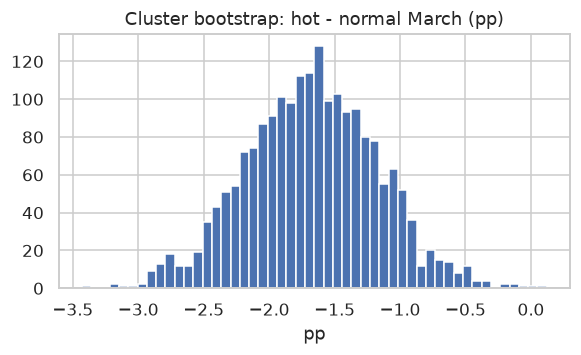

In [14]:
def boot(stat, groups, B=2000):
    ids = groups.unique(); out = []
    idx = {g: np.where(groups == g)[0] for g in ids}
    for _ in range(B):
        pick = rng.choice(ids, size=len(ids), replace=True)
        rows = np.concatenate([idx[g] for g in pick])
        out.append(stat(rows))
    return np.array(out)

y, h = w.yield_rel_anom.to_numpy(), w.hot_march.to_numpy()
diff_stat = lambda rows: y[rows][h[rows]].mean() - y[rows][~h[rows]].mean()
bs = boot(diff_stat, w.unit_id.reset_index(drop=True))
print(f"hot - normal March difference: {diff_stat(np.arange(len(y)))*100:+.2f} pp; cluster-bootstrap 95% CI "
      f"[{np.percentile(bs, 2.5)*100:+.2f}, {np.percentile(bs, 97.5)*100:+.2f}]  (naive CI above was narrower)")

pb = w[(w.state_id.isin([3, 6])) & (w.year == 2021)].yield_rel_anom.dropna().to_numpy()
bm = [rng.choice(pb, len(pb)).mean() for _ in range(5000)]
print(f"Punjab+Haryana 2021-22 mean anomaly {pb.mean()*100:+.1f}% (n={len(pb)} districts), bootstrap 95% CI "
      f"[{np.percentile(bm, 2.5)*100:+.1f}, {np.percentile(bm, 97.5)*100:+.1f}]")
fig, ax = plt.subplots(figsize=(6, 3)); ax.hist(np.array(bs)*100, bins=50); ax.set(title="Cluster bootstrap: hot - normal March (pp)", xlabel="pp")
save(fig, "06_bootstrap_hot_march"); plt.show()

## 10. The main test: does irrigation protect wheat from heat?
Panel regression with **district fixed effects** (each district's own baseline) and **year fixed effects** (anything hitting
all districts in a year: prices, varieties, nationwide weather), and standard errors **clustered by district**:

anomaly_dt = b1 x hot_days_dt + b2 x (hot_days_dt x irr_share_dt) + b3 x irr_share_dt + controls + district FE + year FE + error

If irrigation protects, b1 < 0 (heat hurts rainfed wheat) and **b2 > 0** (the damage shrinks as irrigation rises).
Heat is measured as days > 35 C in March (grain filling) and season night temperature; rain is a control.

In [15]:
d = w.dropna(subset=["yield_rel_anom", "irr_share", "mar_hot_days_35", "tmin_mean", "rain_total"]).copy()   # same rows for model and clusters
d["hot10"] = d.mar_hot_days_35 / 10                 # per 10 hot days, easier to read
d["irr_c"] = d.irr_share - d.irr_share.mean()      # centred: b1 = heat effect at the average irrigation level
f = "yield_rel_anom ~ hot10 * irr_c + tmin_mean + np.log1p(rain_total) + C(unit_id) + C(year)"
fe = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d.unit_id})
keep = ["hot10", "irr_c", "hot10:irr_c", "tmin_mean", "np.log1p(rain_total)"]
res = pd.DataFrame({"coef": fe.params[keep], "se": fe.bse[keep], "p": fe.pvalues[keep]})
res["ci_low"], res["ci_high"] = fe.conf_int().loc[keep, 0], fe.conf_int().loc[keep, 1]
print(f"n = {int(fe.nobs):,} district-years, {d.unit_id.nunique()} districts, clusters = districts")
print(res.round(4).to_string())
for irr in (0.3, 0.6, 0.95):
    eff = fe.params["hot10"] + fe.params["hot10:irr_c"] * (irr - d.irr_share.mean())
    print(f"  effect of +10 hot March days at {irr:.0%} irrigation: {eff*100:+.1f}% of trend yield")

n = 7,914 district-years, 406 districts, clusters = districts
                        coef      se       p  ci_low  ci_high
hot10                -0.0182  0.0076  0.0171 -0.0331  -0.0032
irr_c                -0.0855  0.0374  0.0223 -0.1588  -0.0122
hot10:irr_c           0.0447  0.0274  0.1031 -0.0091   0.0984
tmin_mean            -0.0418  0.0076  0.0000 -0.0566  -0.0270
np.log1p(rain_total)  0.0029  0.0024  0.2125 -0.0017   0.0076
  effect of +10 hot March days at 30% irrigation: -4.2% of trend yield
  effect of +10 hot March days at 60% irrigation: -2.8% of trend yield
  effect of +10 hot March days at 95% irrigation: -1.2% of trend yield


In [16]:
# Robustness: without Madhya Pradesh 2018+ (D15), and rice with drought x irrigation
d2 = d[~((d.state_id == 23) & (d.year >= 2018))]
fe2 = smf.ols(f, data=d2).fit(cov_type="cluster", cov_kwds={"groups": d2.unit_id})
print("without MP 2018+:", fe2.params[["hot10", "hot10:irr_c"]].round(4).to_dict(), "p:", fe2.pvalues[["hot10", "hot10:irr_c"]].round(4).to_dict())

dr = r.dropna(subset=["yield_rel_anom", "irr_share", "rain_dev_pct", "tmax_mean"]).copy()
dr["irr_c"] = dr.irr_share - dr.irr_share.mean()
fr = smf.ols("yield_rel_anom ~ rain_dev_pct * irr_c + tmax_mean + C(unit_id) + C(year)", data=dr).fit(
    cov_type="cluster", cov_kwds={"groups": dr.unit_id})
kr = ["rain_dev_pct", "irr_c", "rain_dev_pct:irr_c", "tmax_mean"]
print(f"\nRICE (n={int(fr.nobs):,}): effect of monsoon rain deviation and its interaction with irrigation")
print(pd.DataFrame({"coef": fr.params[kr], "se": fr.bse[kr], "p": fr.pvalues[kr]}).round(4).to_string())
for irr in (0.2, 0.6, 0.95):
    eff = fr.params["rain_dev_pct"] + fr.params["rain_dev_pct:irr_c"] * (irr - dr.irr_share.mean())
    print(f"  a monsoon 20% below normal at {irr:.0%} irrigation: {-0.2*eff*100:+.1f}% of trend yield")

without MP 2018+: {'hot10': -0.0206, 'hot10:irr_c': 0.0528} p: {'hot10': 0.006, 'hot10:irr_c': 0.0447}



RICE (n=10,494): effect of monsoon rain deviation and its interaction with irrigation
                      coef      se       p
rain_dev_pct        0.0764  0.0108  0.0000
irr_c               0.0645  0.0172  0.0002
rain_dev_pct:irr_c -0.1928  0.0287  0.0000
tmax_mean          -0.0530  0.0058  0.0000
  a monsoon 20% below normal at 20% irrigation: -3.1% of trend yield
  a monsoon 20% below normal at 60% irrigation: -1.6% of trend yield
  a monsoon 20% below normal at 95% irrigation: -0.3% of trend yield


## 11. What we can and cannot claim (written after reviewing the outputs)
**Supported (robust to the trustworthy methods):**
- Warmer wheat nights lower yield: about -4% per +1 C in the season mean minimum, p < 0.001 with district and year
  fixed effects and clustered errors; significant in UP, MP, Punjab and Gujarat after Bonferroni correction.
- More hot March days lower wheat yield: about -1.8% per 10 extra days at average irrigation (p = 0.02).
- **Irrigation buffers rice against monsoon deficits**: a 20% rain deficit costs about 3% of yield at 20% irrigation
  but about 0.3% at 95% (interaction p < 0.0001).

**Not established:**
- That irrigation buffers *wheat* against March heat. The estimate points that way (-4.2% at 30% irrigation vs -1.2% at 95%)
  but p = 0.10; it reaches p = 0.045 only after dropping Madhya Pradesh 2018+. Treat as suggestive, not shown.

**Method lessons visible here:** heavy tails (kurtosis about 23) make ANOVA and Kruskal-Wallis disagree; loss-year counts are
overdispersed relative to a binomial (districts differ in risk); hot-day counts are overdispersed relative to a Poisson
even within one district; the cluster bootstrap CI is wider than the naive one; the simulated Type I error rate is 5%.